# Question A: Do "star" authors drive citations?

**AFS Journal Citation Analytics, Financial Services Review (FSR).** Brief (`DSB300 Projects 2026.pdf`, p.4-5):

> Are citations concentrated among a small number of prolific or well-known authors, and does an author's prior track record predict how their FSR papers perform?

The notebook answers four sub-questions in order:

1. **Concentration.** How much of the citation total is held by the top few authors, and is FSR different from its two comparators (Financial Planning Review, FPR; Journal of Financial Counseling and Planning, JFCP)?
2. **Prolific or well-known?** Are the most-cited FSR authors the ones who publish most in FSR, the ones with the biggest external reputation (h-index), or neither?
3. **Prediction.** Controlling for paper age, team size and topic, does an author's track record before the paper was published predict the paper's citation count, and does that hold out of sample?
4. **Journal spread.** Does anyone publish in all three journals, and are highly cited authors the ones who stay in a single journal?

All data come from `data/*.csv`, built once by `build_dataset.py` (Scopus export enriched with OpenAlex author and journal records). How every column was collected and constructed is documented in `DATA.md`. Topics come from Question B's final model, NMF with k = 11: §4.1 reruns Question B's own preprocessing and model code and checks that it reproduces the topic assignments stored in `data/papers.csv`.

## 1. Setup

Load the tables. Identifier columns are read as strings so that Scopus and OpenAlex ids are never coerced to numbers, and empty strings (unmatched authors, missing DOIs) become `NaN`.

In [1]:
import re
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
from nltk.stem import WordNetLemmatizer
from scipy.stats import mannwhitneyu, spearmanr
from sklearn.decomposition import NMF
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, TfidfVectorizer
from statsmodels.stats.outliers_influence import variance_inflation_factor

warnings.filterwarnings("ignore", category=RuntimeWarning)

DATA = "../data"
IDS = {"scopus_author_id": str, "openalex_author_id": str}

def load(name, **kwargs):
    return pd.read_csv(f"{DATA}/{name}.csv", keep_default_na=False, na_values=[""], **kwargs)

papers = load("papers")
paper_authors = load("paper_authors", dtype=IDS)
authors = load("authors", dtype=IDS)
topics = load("topics")
len(papers), len(paper_authors), len(authors), len(topics)

(1360, 3336, 1953, 11)

## 2. Data overview

- `papers`: one row per Scopus paper (1360). Outcome is `cited_by` (Scopus citation count, September 2026). Team track-record columns (`team_prior_works_max`, `team_prior_cites_max`, `team_h_index_max`) are the maximum over the paper's co-authors that were matched to OpenAlex; `prior_*` count only years strictly before the paper's publication year, `h_index` is a 2026 snapshot.
- `paper_authors`: one row per paper x author (3336), the long table behind both of the others.
- `authors`: one row per Scopus author id (1953) with corpus counts, OpenAlex career stats and a dominant research theme.
- `journals`: OpenAlex source records for the three journals. Its `two_yr_mean_citedness`, the journal impact factor proxy, is copied onto `papers` as `journal_2yr_citedness`, so the table itself is not loaded here.
- `topics`: the 11 NMF topics of the Question B model, with short labels and top terms.

Coverage matters for the model later: 91.5% of authors are matched to OpenAlex and 96.8% of papers have at least one matched author.

In [2]:
papers["period"] = (papers.year // 5 * 5).astype(str) + "-" + (papers.year // 5 * 5 + 4).astype(str)
print(pd.crosstab(papers.period, papers.journal))
papers.groupby("journal").cited_by.describe()[["count", "mean", "50%", "max"]].round(1)

journal    FPR  FSR  JFCP
period                   
1990-1994    0   30    35
1995-1999    0   87    81
2000-2004    0  107    74
2005-2009    0   95    61
2010-2014    0  100    53
2015-2019   17   80   118
2020-2024   53   83   152
2025-2029   41   43    50


,count,mean,50%,max
journal,,,,
FPR,111.0,7.8,3.0,191.0
FSR,625.0,14.2,4.0,678.0
JFCP,624.0,25.8,10.0,564.0


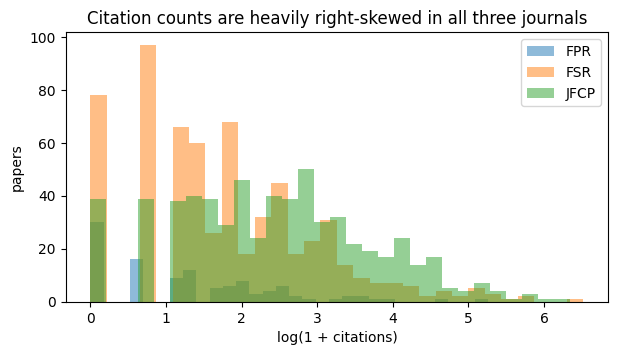

In [3]:
fig, ax = plt.subplots(figsize=(7, 3.5))
for j, g in papers.groupby("journal"):
    ax.hist(np.log1p(g.cited_by), bins=30, alpha=0.5, label=j)
ax.set_xlabel("log(1 + citations)")
ax.set_ylabel("papers")
ax.set_title("Citation counts are heavily right-skewed in all three journals")
ax.legend()
plt.show()

In [4]:
cov = papers.groupby("journal").agg(
    n_papers=("paper_id", "size"),
    resolved_to_openalex=("resolution", lambda s: (s != "unresolved").mean()),
    has_matched_author=("n_authors_matched", lambda s: (s > 0).mean()),
)
cov["authors_matched"] = [
    authors.loc[authors[f"n_papers_{j.lower()}"] > 0, "openalex_author_id"].notna().mean() for j in cov.index
]
cov.round(3)

,n_papers,resolved_to_openalex,has_matched_author,authors_matched
journal,,,,
FPR,111,1.000,1.000,0.990
FSR,625,0.998,0.987,0.953
JFCP,624,0.808,0.944,0.880


## 3. Citation concentration

Each co-author is credited with the paper's full citation count (full counting). Three summaries per journal:

- **Top-k share**: the share of all citations held by the top 1%, 5% and 10% of authors. This is the literal answer to "are citations concentrated among a small number of authors".
- **Gini coefficient**: 0 means every author has the same total, 1 means one author has everything.
- **Lorenz curve**: cumulative share of citations against cumulative share of authors, ranked from least to most cited.

The paper-level version is shown first as a reference point. If a handful of papers hold most citations and most authors have only one paper, author-level concentration follows mechanically, whoever the authors are.

In [5]:
def top_share(x, pct):
    x = np.sort(np.asarray(x, float))[::-1]
    return x[: max(1, round(len(x) * pct))].sum() / x.sum()

def gini(x):
    x = np.sort(np.asarray(x, float))
    n = len(x)
    return (2 * np.arange(1, n + 1) * x).sum() / (n * x.sum()) - (n + 1) / n

# paper level first, as the reference point
papers.groupby("journal").cited_by.agg(
    n_papers="size", top10pct_share=lambda s: top_share(s, 0.10), gini=gini
).round(3)

,n_papers,top10pct_share,gini
journal,,,
FPR,111,0.638,0.759
FSR,625,0.646,0.755
JFCP,624,0.527,0.676


In [6]:
author_cites = (paper_authors.merge(papers[["paper_id", "journal", "cited_by"]])
                .groupby(["journal", "scopus_author_id"]).cited_by.sum())

author_cites.groupby(level="journal").agg(
    n_authors="size",
    top1pct_share=lambda s: top_share(s, 0.01),
    top5pct_share=lambda s: top_share(s, 0.05),
    top10pct_share=lambda s: top_share(s, 0.10),
    gini=gini,
).round(3)

,n_authors,top1pct_share,top5pct_share,top10pct_share,gini
journal,,,,,
FPR,203,0.172,0.435,0.602,0.735
FSR,966,0.243,0.523,0.663,0.762
JFCP,1006,0.250,0.533,0.660,0.765


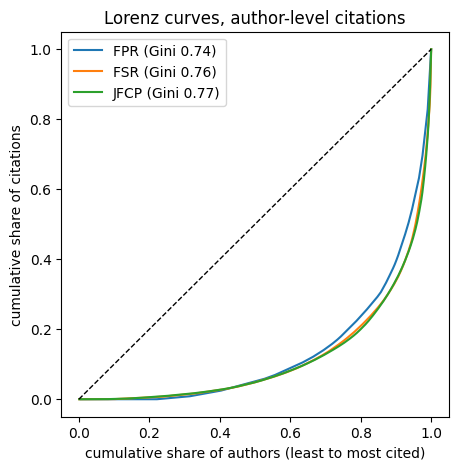

In [7]:
fig, ax = plt.subplots(figsize=(5, 5))
for j, s in author_cites.groupby(level="journal"):
    x = np.sort(s.values)
    ax.plot(np.arange(1, len(x) + 1) / len(x), np.cumsum(x) / x.sum(), label=f"{j} (Gini {gini(x):.2f})")
ax.plot([0, 1], [0, 1], "k--", lw=1)
ax.set_xlabel("cumulative share of authors (least to most cited)")
ax.set_ylabel("cumulative share of citations")
ax.set_title("Lorenz curves, author-level citations")
ax.legend()
plt.show()

### 3.1 Who are FSR's most-cited authors?

Top 15 FSR authors by FSR citations, with how many FSR papers produced those citations and the author's career h-index from OpenAlex.

In [8]:
cols = ["scopus_name", "openalex_name", "n_papers_fsr", "cites_fsr", "h_index", "oa_suspect", "institution"]
(authors.sort_values(["cites_fsr", "scopus_name"], ascending=[False, True])
 .head(15)[cols].reset_index(drop=True))

,scopus_name,openalex_name,n_papers_fsr,cites_fsr,h_index,oa_suspect,institution
0,Chen,Haiyang Chen,3,1074,24.0,False,Tiangong University
1,Volpe,Ronald P. Volpe,3,1074,5.0,False,NaN
2,Grable,John E. Grable,10,531,44.0,False,University of Georgia
3,Lytton,Ruth H. Lytton,3,458,8.0,False,NaN
4,Faff,Robert W. Faff,2,293,0.0,False,Monash University
5,Hanna,Sherman D. Hanna,14,291,30.0,False,The Ohio State University
6,Hallahan,Terrence Hallahan,1,279,10.0,False,Jadara University
7,McKenzie,Michael D. McKenzie,1,279,30.0,False,Coastal Carolina University
8,Baker,H. Kent Baker,6,275,50.0,True,American University
9,Montalto,Catherine P. Montalto,6,252,22.0,False,The Ohio State University


### 3.2 Prolific or well-known?

The brief asks about "prolific or well-known" authors as if they were the same group. Among FSR authors with at least two FSR papers, this compares three rankings: FSR citations (impact), FSR paper count (prolific) and career h-index (well-known). Spearman correlations show how similar the rankings are, and the number of names shared by the top-20 lists shows how far the groups overlap.

In [9]:
rep = authors[(authors.n_papers_fsr >= 2) & authors.h_index.notna()]
three = ["cites_fsr", "n_papers_fsr", "h_index"]
print(len(rep), "FSR authors with 2+ FSR papers and an OpenAlex match")

top20 = {c: set(rep.nlargest(20, c).scopus_author_id) for c in three}
for a, b in [("cites_fsr", "n_papers_fsr"), ("cites_fsr", "h_index"), ("n_papers_fsr", "h_index")]:
    print(f"top-20 names shared by {a} and {b}: {len(top20[a] & top20[b])}")

rep[three].corr(method="spearman").round(2)

241 FSR authors with 2+ FSR papers and an OpenAlex match
top-20 names shared by cites_fsr and n_papers_fsr: 6
top-20 names shared by cites_fsr and h_index: 5
top-20 names shared by n_papers_fsr and h_index: 3


,cites_fsr,n_papers_fsr,h_index
cites_fsr,1.00,0.41,0.30
n_papers_fsr,0.41,1.00,0.27
h_index,0.30,0.27,1.00


**Reading.** Citations are highly concentrated in every journal: in FSR the top 10% of authors hold 66% of citations and the top 1% hold 24% (Gini 0.76). FPR and JFCP look the same (top 10% hold 60% and 66%), so this is the shape of the field, not something FSR does differently. Paper-level concentration in FSR is almost identical (top 10% of papers hold 65%, Gini 0.76), which is the first hint that "concentrated among authors" is mostly "concentrated among papers" relabelled.

Prolific and well-known are different groups. Among repeat FSR authors the rank correlation between FSR citations and FSR paper count is 0.41, and between FSR citations and career h-index 0.30. The top-20 lists by these three criteria share only three to six names. An editor looking for "stars" would pick different people depending on which definition they used.

## 4. Paper and author themes

Question A uses Question B's final topic model, non-negative matrix factorisation (NMF) with k = 11, so both questions share one partition of the corpus. Question B compared LDA, NMF and BERTopic over k = 4 to 19 and selected NMF with k = 11 on coherence and interpretability; that comparison is not repeated here. §4.1 copies Question B's preprocessing and model code and refits the selected model.

A paper's topic is its largest component weight; the `topic_w0..10` columns keep the full normalised weight vector. Topic labels are Question B's (report Table B1). An author's theme is the largest component of the mean weight vector over their papers, and `theme_share` is the fraction of their papers whose own topic is that theme.

Themes serve two purposes here: they describe what FSR publishes relative to JFCP, and they enter the citation model as controls so that an author's track record is not credited for the topic they happen to work on.

### 4.1 Question B's topic model (k = 11)

The first cell below repeats Question B's preprocessing on `master_dataset.csv`: combine title, abstract and author keywords, lower-case, strip non-letters, remove English and Question B's custom stop words, lemmatise, and build the TF-IDF matrix (1-3 grams, `min_df=5`, `max_df=0.85`). The second fits NMF with Question B's settings at the selected k = 11. Question B's k-search, LDA and BERTopic cells are left out, because they choose the model rather than define it and need gensim and BERTopic.

The assertions check that the refitted model gives every paper the same topic as `data/papers.csv` and every topic the same top terms as `data/topics.csv`. The 1,362 Scopus rows include two papers with no author id, which are not in `papers`.

In [10]:
citation_df = pd.read_csv(f"{DATA}/master_dataset.csv")
citation_df["combined_text"] = (
    citation_df["title"].fillna("") + " "
    + citation_df["abstract"].fillna("") + " "
    + citation_df["author_keywords"].fillna("").str.replace(";", " ")
)

custom_stopwords = {
    "study", "results", "paper", "research", "article",
    "using", "based", "data", "analysis", "findings",
    "significant", "significantly",
    "academy", "service", "services",
    "right", "rights", "reserved",
}
stop_words = set(ENGLISH_STOP_WORDS).union(custom_stopwords)
lemmatizer = WordNetLemmatizer()

def clean_text(text):
    text = re.sub(r"[^a-z\s]", " ", text.lower())
    return " ".join(lemmatizer.lemmatize(t) for t in text.split() if t not in stop_words)

citation_df["cleaned_text"] = citation_df["combined_text"].apply(clean_text)
tfidf_vectorizer = TfidfVectorizer(max_df=0.85, min_df=5, ngram_range=(1, 3))
tfidf_matrix = tfidf_vectorizer.fit_transform(citation_df["cleaned_text"])

In [11]:
nmf_model = NMF(n_components=11, random_state=42, init="nndsvda", max_iter=500)
W = nmf_model.fit_transform(tfidf_matrix)

kept = citation_df["authors_id"].notna().to_numpy()  # the 1360 rows in papers
assert (W[kept].argmax(axis=1) == papers.topic_id.to_numpy()).all()

terms = tfidf_vectorizer.get_feature_names_out()
top_terms = [", ".join(terms[i] for i in h.argsort()[-10:][::-1]) for h in nmf_model.components_]
assert top_terms == topics.top_terms.tolist()

for k, (label, words) in enumerate(zip(topics.topic_label, top_terms)):
    print(f"{k:2d} {label:28s} {words}")

 0 Retirement Planning          retirement, saving, retirement saving, plan, retirement planning, age, social security, pension, income, retiree
 1 Mutual Funds                 fund, mutual, mutual fund, performance, return, investor, fund performance, expense, ratio, mutual fund performance
 2 Financial Literacy           literacy, financial literacy, knowledge, financial education, education, financial knowledge, program, education financial, confidence, literacy financial
 3 Risk Tolerance               risk, tolerance, risk tolerance, financial risk, financial risk tolerance, measure, investment, aversion, assessment, risk taking
 4 Credit and Debt              credit, card, credit card, debt, consumer, credit card debt, card debt, payment, use, cash
 5 Portfolio Investment         portfolio, stock, investor, market, asset, investment, allocation, return, bond, risk
 6 Household Finance            household, consumer, survey consumer finance, survey consumer, consumer finance, inco

In [12]:
topics.set_index("topic_label")[["n_papers", "n_papers_fsr", "n_papers_jfcp", "n_papers_fpr"]]

,n_papers,n_papers_fsr,n_papers_jfcp,n_papers_fpr
topic_label,,,,
Retirement Planning,88,45,40,3
Mutual Funds,82,74,7,1
Financial Literacy,90,35,46,9
Risk Tolerance,73,30,36,7
Credit and Debt,44,19,24,1
Portfolio Investment,196,166,19,11
Household Finance,198,58,137,3
Financial Advice,152,65,28,59
Student Finance,95,35,59,1


                             n_papers  mean_cites  median_cites  \
topic_label                                                       
Risk Tolerance                     30       51.53           8.5   
Financial Literacy                 35       26.77           6.0   
Student Finance                    35       34.86           3.0   
Financial Behaviour                35       12.63           2.0   
Financial Advice                   65        9.57           3.0   
Household Finance                  58       12.74           4.0   
Credit and Debt                    19        7.74           3.0   
Mutual Funds                       74       11.42           6.0   
Portfolio Investment              166        8.67           4.0   
Retirement Planning                45        8.33           3.0   
Tax and Retirement Accounts        63        8.52           2.0   

                             mean_cites_per_year  
topic_label                                       
Risk Tolerance            

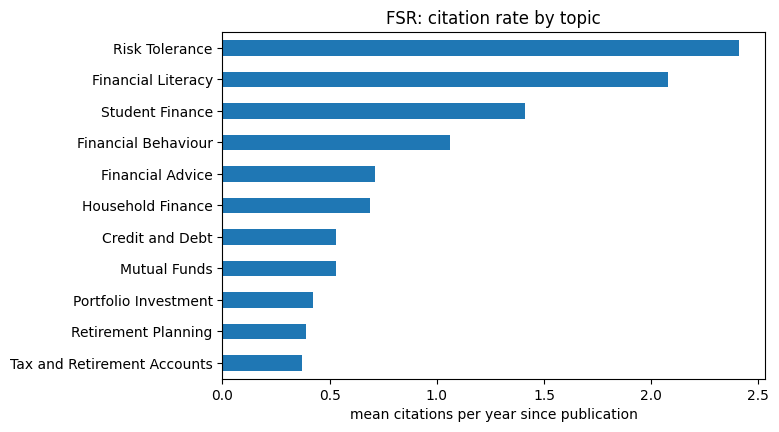

In [13]:
fsr = papers[papers.journal == "FSR"].assign(cites_per_year=lambda t: t.cited_by / t.paper_age)
by_topic = (fsr.groupby("topic_label")
            .agg(n_papers=("paper_id", "size"), mean_cites=("cited_by", "mean"),
                 median_cites=("cited_by", "median"), mean_cites_per_year=("cites_per_year", "mean"))
            .sort_values("mean_cites_per_year", ascending=False)
            .round(2))
print(by_topic)

fig, ax = plt.subplots(figsize=(7, 4.5))
by_topic.mean_cites_per_year.plot.barh(ax=ax)
ax.invert_yaxis()
ax.set_xlabel("mean citations per year since publication")
ax.set_ylabel("")
ax.set_title("FSR: citation rate by topic")
plt.show()

In [14]:
# authors.csv still carries older label wording, so relabel themes from topics.csv
authors["theme_label"] = authors.theme_id.map(topics.set_index("topic_id").topic_label)

fsr_rep = authors[authors.n_papers_fsr >= 2]
print(f"{len(fsr_rep)} repeat FSR authors, mean theme_share {fsr_rep.theme_share.mean():.2f}")
(fsr_rep.groupby("theme_label")
 .agg(n_authors=("scopus_author_id", "size"), mean_theme_share=("theme_share", "mean"))
 .reset_index()
 .sort_values(["n_authors", "theme_label"], ascending=[False, True])
 .set_index("theme_label")
 .round(2))

241 repeat FSR authors, mean theme_share 0.60


,n_authors,mean_theme_share
theme_label,,
Portfolio Investment,60,0.66
Financial Advice,25,0.52
Mutual Funds,25,0.65
Tax and Retirement Accounts,23,0.66
Retirement Planning,22,0.67
Financial Behaviour,21,0.44
Financial Literacy,19,0.52
Household Finance,19,0.54
Risk Tolerance,12,0.59


**Reading.** FSR's output is dominated by investment and retirement topics: Portfolio Investment (166 of 625 papers), Mutual Funds (74), Tax and Retirement Accounts (63) and Retirement Planning (45) together make up 56% of the journal, and each draws about 0.5 citations per paper-year or fewer. The most-cited FSR topics are Risk Tolerance (2.4 per year) and Financial Literacy (2.1), followed by Student Finance (1.4) and Financial Behaviour (1.1), each with 35 or fewer FSR papers; JFCP publishes far more on Financial Behaviour (214 papers against 35) and Household Finance (137 against 58). The Student Finance mean is lifted by the two most-cited FSR papers (Chen and Volpe's 1998 and 2002 studies of financial literacy among college students), which the topic model assigns there. Repeat FSR authors have the same skew: 60 of 241 work mainly on Portfolio Investment and 130 on one of the four investment, retirement and tax topics, and most stay in one lane (a repeat author's theme covers 60% of their papers on average). This is why topic has to be controlled for before crediting an author's track record with their citations.

## 5. Does track record predict an FSR paper's citations?

**Unit and outcome.** One row per FSR paper; outcome is `cited_by`. Citation counts are non-negative integers with a variance far above the mean (about 14 and 1800 here), so a Poisson model is ruled out and a negative binomial (NB2) is used. Exponentiated coefficients are incidence rate ratios (IRR): the multiplicative change in expected citations for a one-unit change in the predictor.

**Sample.** FSR papers with at least one OpenAlex-matched co-author (the track-record columns are otherwise undefined) and a topic assignment. 8 of 625 FSR papers are dropped.

**Predictors.** Track record: `log_prior_cites` = log(1 + citations the best-established co-author had received before the paper's year), `log_prior_works` = the same for works, `h_index` = that co-author's h-index today. Controls: `log_age` (citations accumulate roughly log-linearly with age), `n_authors`, and dominant-topic dummies with Portfolio Investment, the largest FSR topic, as reference. Question B enters the same topics as proportions with Retirement Planning as reference, so topic IRRs differ in size between the two questions even though the topic assignments are identical.

**Collinearity check first.** NB coefficients are only interpretable one at a time if the predictors are not near-linear combinations of each other. The three track-record measures all summarise the same career, so a variance inflation factor (VIF) check is run before fitting, and any predictor with a VIF above 5 is dropped.

In [15]:
d = papers[(papers.journal == "FSR") & (papers.n_authors_matched > 0) & (papers.topic_id >= 0)].copy()
print(f"FSR sample: {len(d)} papers ({(papers.journal == 'FSR').sum() - len(d)} dropped)")
print(f"cited_by mean {d.cited_by.mean():.1f}, variance {d.cited_by.var():.0f}, zero share {(d.cited_by == 0).mean():.3f}")

d["log_prior_cites"] = np.log1p(d.team_prior_cites_max)
d["log_prior_works"] = np.log1p(d.team_prior_works_max)
d["h_index"] = d.team_h_index_max
d["log_age"] = np.log(d.paper_age)
cont = ["log_prior_cites", "log_prior_works", "h_index", "n_authors", "log_age"]

ref_topic = "Portfolio Investment"  # FSR's largest topic
print(f"reference topic: {ref_topic} ({(d.topic_label == ref_topic).sum()} papers)")
topic_dummies = pd.get_dummies(d.topic_label, prefix="topic").astype(float).drop(columns=f"topic_{ref_topic}")
X = sm.add_constant(pd.concat([d[cont], topic_dummies], axis=1))
y = d.cited_by

FSR sample: 617 papers (8 dropped)
cited_by mean 14.2, variance 1818, zero share 0.123
reference topic: Portfolio Investment (166 papers)


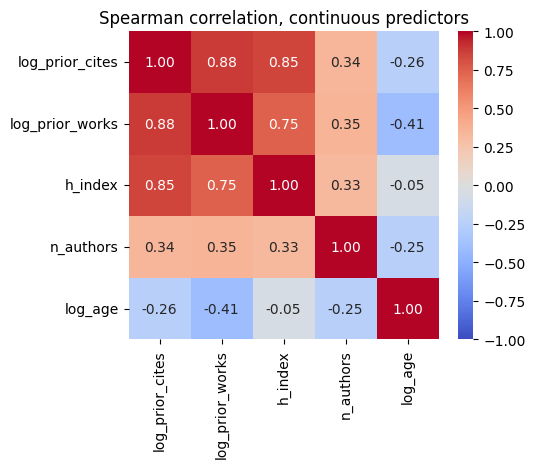

In [16]:
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(d[cont].corr(method="spearman"), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
ax.set_title("Spearman correlation, continuous predictors")
plt.show()

### 5.1 Variance inflation factors

VIF for predictor *j* is 1 / (1 - R²) from regressing it on all other predictors; 5 is the usual cut-off.

In [17]:
def vif_table(X):
    vif = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
    return pd.Series(vif, index=X.columns).drop("const")

print(vif_table(X)[cont].round(2))

# log_prior_works is the only predictor above 5
keep = [c for c in X.columns if c not in ("const", "log_prior_works")]
keep_cont = [c for c in cont if c in keep]
vif_table(X[["const"] + keep]).round(2)

log_prior_cites    5.93
log_prior_works    6.50
h_index            2.21
n_authors          1.28
log_age            1.65
dtype: float64


log_prior_cites                      2.32
h_index                              2.09
n_authors                            1.28
log_age                              1.34
topic_Credit and Debt                1.09
topic_Financial Advice               1.31
topic_Financial Behaviour            1.27
topic_Financial Literacy             1.23
topic_Household Finance              1.25
topic_Mutual Funds                   1.27
topic_Retirement Planning            1.19
topic_Risk Tolerance                 1.14
topic_Student Finance                1.16
topic_Tax and Retirement Accounts    1.25
dtype: float64

### 5.2 Main model

`log_prior_works` is dropped (VIF 6.5; it is 0.88 rank-correlated with `log_prior_cites`). `log_prior_cites` and `h_index` stay in, but they are still 0.85 rank-correlated, so their individual coefficients split one underlying "established author" effect between them. A joint Wald test on the pair is reported alongside the individual IRRs, and a leak-free variant without the 2026 `h_index` snapshot shows what the point-in-time measure does on its own.

In [18]:
def fit_nb(y, X):
    res = sm.NegativeBinomial(y, X).fit(maxiter=1000, disp=0)
    if not res.mle_retvals["converged"]:
        # fall back to Nelder-Mead, then polish with BFGS
        start = sm.NegativeBinomial(y, X).fit(method="nm", maxiter=5000, disp=0).params
        res = sm.NegativeBinomial(y, X).fit(start_params=start, method="bfgs", maxiter=1000, disp=0)
    assert res.mle_retvals["converged"]
    return res

def irr_table(res):
    ci = np.exp(res.conf_int())
    out = pd.DataFrame({"IRR": np.exp(res.params), "ci_low": ci[0], "ci_high": ci[1], "p": res.pvalues})
    return out.drop("alpha").round(3)

main = fit_nb(y, X[["const"] + keep])
wald = main.wald_test("log_prior_cites = 0, h_index = 0", scalar=True)
print(f"n = {int(main.nobs)}, alpha = {main.params['alpha']:.2f}, pseudo R2 = {main.prsquared:.3f}")
print(f"joint Wald test of prior cites and h-index: chi2(2) = {float(wald.statistic):.1f}, p = {float(wald.pvalue):.1e}")
irr_table(main)

n = 617, alpha = 1.32, pseudo R2 = 0.082
joint Wald test of prior cites and h-index: chi2(2) = 25.3, p = 3.1e-06


,IRR,ci_low,ci_high,p
const,0.080,0.041,0.155,0.000
log_prior_cites,1.024,0.955,1.098,0.509
h_index,1.016,1.006,1.027,0.001
n_authors,1.062,0.944,1.195,0.318
log_age,3.942,3.365,4.618,0.000
topic_Credit and Debt,1.206,0.643,2.260,0.559
topic_Financial Advice,1.948,1.340,2.832,0.000
topic_Financial Behaviour,3.479,2.131,5.677,0.000
topic_Financial Literacy,7.125,4.507,11.262,0.000
topic_Household Finance,1.716,1.175,2.507,0.005


In [19]:
leakfree = fit_nb(y, X[["const"] + [c for c in keep if c != "h_index"]])
print(f"model without h_index: pseudo R2 = {leakfree.prsquared:.3f}")
irr_table(leakfree).loc[["log_prior_cites"]]

model without h_index: pseudo R2 = 0.079


,IRR,ci_low,ci_high,p
log_prior_cites,1.11,1.057,1.167,0.0


**Reading.** Track record is associated with citations, but modestly. Jointly the two track-record terms are clearly non-zero (Wald p < 0.001). Taken alone, `h_index` carries the effect in the full model (IRR 1.016 per h-index point: an author with h-index 20 rather than 10 is associated with about 18% more citations on the paper), while `log_prior_cites` adds nothing once `h_index` is in. Without `h_index`, the leak-free prior-citations measure is significant on its own: doubling the best co-author's prior citations is associated with about 8% more citations (IRR 1.11 per log unit, 2^0.104). Both pictures say the same thing, one underlying effect of modest size.

Compare that with the controls. Each doubling of paper age multiplies expected citations by about 2.6 (IRR 3.94 per log unit). Topic matters far more than the author: relative to a Portfolio Investment paper of the same age and team, a Financial Literacy paper attracts about 7 times the citations, a Risk Tolerance paper about 4.7 times, and Financial Behaviour and Student Finance papers about 3.5 and 3.3 times. Mutual Funds, Retirement Planning, Tax and Retirement Accounts and Credit and Debt are indistinguishable from the reference. Pseudo R² is 0.08; most variation in FSR citations is explained by none of these.

### 5.3 Pooled robustness and the journal impact factor

The same specification on all three journals, adding journal identity. This is where the journal impact factor (`journal_2yr_citedness`, OpenAlex's two-year mean citedness: FSR 0.48, FPR 1.02, JFCP 1.47) has to be handled with care: with three journals it takes exactly three values, one per journal, so it is a linear combination of the journal dummies. The VIF table makes this visible (VIF effectively infinite) and the citedness column is dropped, leaving the journal dummies to carry the same information.

In [20]:
p = papers[(papers.n_authors_matched > 0) & (papers.topic_id >= 0)].copy()
p["log_prior_cites"] = np.log1p(p.team_prior_cites_max)
p["h_index"] = p.team_h_index_max
p["log_age"] = np.log(p.paper_age)
jd = pd.get_dummies(p.journal, prefix="journal").astype(float).drop(columns="journal_FSR")
td = pd.get_dummies(p.topic_label, prefix="topic").astype(float).drop(columns=f"topic_{ref_topic}")
Xp = sm.add_constant(pd.concat([p[keep_cont + ["journal_2yr_citedness"]], jd, td], axis=1))

# one citedness value per journal, so it is a linear combination of the journal dummies
with warnings.catch_warnings():
    warnings.simplefilter("ignore")  # statsmodels warns the matrix is singular, which is the point
    print(vif_table(Xp)[["journal_2yr_citedness", "journal_FPR", "journal_JFCP"]])
Xp = Xp.drop(columns="journal_2yr_citedness")
print(f"max VIF after dropping it: {vif_table(Xp).max():.2f}")

pooled = fit_nb(p.cited_by, Xp)
print(f"pooled NB: n = {int(pooled.nobs)}, pseudo R2 = {pooled.prsquared:.3f}")
irr_table(pooled).loc[keep_cont + list(jd.columns)]

journal_2yr_citedness    1.000800e+15
journal_FPR              1.000800e+15
journal_JFCP             1.000800e+15
dtype: float64


max VIF after dropping it: 2.60
pooled NB: n = 1317, pseudo R2 = 0.084


,IRR,ci_low,ci_high,p
log_prior_cites,1.124,1.076,1.174,0.000
h_index,1.004,0.998,1.010,0.162
n_authors,0.985,0.929,1.045,0.619
log_age,3.875,3.510,4.278,0.000
journal_FPR,2.023,1.507,2.714,0.000
journal_JFCP,1.688,1.431,1.992,0.000


### 5.4 Temporal holdout

An in-sample association is not a prediction. The model is refit on FSR papers published before 2018 and used to rank the 2018 and later papers it has never seen. The score is the Spearman correlation between predicted and actual citation counts. Four nested specifications separate what track record adds from what topic adds.

In [21]:
train, test = d.year < 2018, d.year >= 2018
specs = {
    "age + team size": ["log_age", "n_authors"],
    "+ track record": ["log_age", "n_authors", "log_prior_cites", "h_index"],
    "+ topic": ["log_age", "n_authors"] + list(topic_dummies.columns),
    "+ track record + topic": keep,
}
rho = {}
for name, cols in specs.items():
    res = fit_nb(y[train], X.loc[train, ["const"] + cols])
    rho[name] = spearmanr(res.predict(X.loc[test, ["const"] + cols]), y[test])[0]
print(f"trained on {train.sum()} papers, tested on {test.sum()}")
pd.Series(rho, name="spearman").round(3)

trained on 473 papers, tested on 144


age + team size           0.256
+ track record            0.298
+ topic                   0.285
+ track record + topic    0.324
Name: spearman, dtype: float64

### 5.5 Sensitivity: suspect OpenAlex profiles

OpenAlex sometimes merges several people into one author record; 53 matched authors have more than 300 works and are flagged `oa_suspect`. Refit the main model without papers that have any suspect co-author.

In [22]:
suspect_paper = paper_authors.merge(authors[["scopus_author_id", "oa_suspect"]]).groupby("paper_id").oa_suspect.any()
clean = ~d.paper_id.map(suspect_paper).fillna(False).astype(bool)
robust = fit_nb(y[clean], X.loc[clean, ["const"] + keep])
print(f"papers kept: {clean.sum()} of {len(d)}")
pd.DataFrame({"all papers": irr_table(main).IRR, "no suspect profiles": irr_table(robust).IRR}).loc[keep_cont]

papers kept: 578 of 617


,all papers,no suspect profiles
log_prior_cites,1.024,0.994
h_index,1.016,1.027
n_authors,1.062,1.084
log_age,3.942,3.804


**Reading.** Out of sample, track record helps a little: ranking unseen 2018+ papers improves from Spearman 0.26 (age and team size only) to 0.30 with track record, and to 0.32 with topic as well; topic alone gets 0.28. The gain is real but small, and the same order as what topic gives. Dropping the 39 papers with a suspect OpenAlex profile shifts weight from `log_prior_cites` to `h_index` (the two are collinear, so the split between them is unstable) but leaves the combined track-record effect and every control where they were, so merged profiles are not driving the result.

## 6. Do highly cited authors publish in only one journal?

Each author is classified by how many of the three journals they have published in (`n_journals`). Three things get in the way of a raw comparison. An author with more papers has more chances both to collect citations and to appear in a second journal; nobody could publish in FPR before its first issue in 2018; and JFCP papers are cited at a higher rate than FSR's, so an author's journal mix moves their citation total.

The analysis therefore runs in four steps: counts and the list of three-journal authors; a descriptive table by `n_journals`; a negative binomial model of an author's corpus citations (full counting, as in §3) on two- and three-journal indicators, holding log paper count, log mean paper age and the shares of the author's papers in FSR and FPR constant (JFCP is the reference), fitted to repeat authors (2+ papers, the only ones who can appear in two journals) and refitted on all authors; and a check on career reputation, which does not depend on which journal published the corpus papers. Finally the FSR paper-level model from §5.2 is refitted with an indicator for whether any co-author had already published in JFCP or FPR before the FSR paper's year, the same strictly-before rule as the track-record columns.

In [23]:
J3 = ["fsr", "fpr", "jfcp"]
authors["n_journals"] = (authors[[f"n_papers_{j}" for j in J3]] > 0).sum(axis=1)
authors["journals"] = authors.apply(lambda r: " + ".join(j.upper() for j in J3 if r[f"n_papers_{j}"] > 0), axis=1)

counts = authors.n_journals.value_counts().sort_index().rename("authors").to_frame()
counts["share"] = (counts.authors / len(authors)).round(3)
print(counts, "\n")
print(authors.journals.value_counts(), "\n")
pd.crosstab(pd.cut(authors.n_papers, [0, 1, 2, 4, np.inf], labels=["1 paper", "2", "3-4", "5+"]), authors.n_journals)

            authors  share
n_journals                
1              1775  0.909
2               134  0.069
3                44  0.023 

journals
JFCP                852
FSR                 806
FPR                 117
FSR + JFCP           92
FSR + FPR + JFCP     44
FSR + FPR            24
FPR + JFCP           18
Name: count, dtype: int64 



n_journals,1,2,3
n_papers,,,
1 paper,1454,0,0
2,203,47,0
3-4,90,45,12
5+,28,42,32


In [24]:
three_j = authors[authors.n_journals == 3].assign(name=lambda t: t.openalex_name.fillna(t.scopus_name))
cols = ["name", "n_papers", "n_papers_fsr", "n_papers_fpr", "n_papers_jfcp", "cites_total", "h_index"]
three_j.sort_values(["cites_total", "name"], ascending=[False, True])[cols].reset_index(drop=True)

,name,n_papers,n_papers_fsr,n_papers_fpr,n_papers_jfcp,cites_total,h_index
0,Sherman D. Hanna,53,14,3,36,1943,30.0
1,John E. Grable,36,10,3,23,1750,44.0
2,Jing Jian Xiao,20,1,2,17,1112,50.0
3,Cliff A. Robb,8,2,2,4,650,20.0
4,Swarn Chatterjee,16,3,3,10,533,27.0
5,Vickie L. Bajtelsmit,9,4,3,2,441,14.0
6,Angela Lyons,5,1,1,3,429,27.0
7,Kristy L. Archuleta,11,2,1,8,426,22.0
8,Stuart J. Heckman,14,8,2,4,274,13.0
9,HanNa Lim,12,5,3,4,237,12.0


In [25]:
authors["cites_per_paper"] = authors.cites_total / authors.n_papers
top_cut = authors.cites_total.quantile(0.9)
authors["top10"] = authors.cites_total >= top_cut

def by_spread(df):
    return df.groupby("n_journals").agg(
        authors=("scopus_author_id", "size"), median_papers=("n_papers", "median"),
        median_cites=("cites_total", "median"), median_cites_per_paper=("cites_per_paper", "median"),
        top10_share=("top10", "mean"), median_h_index=("h_index", "median")).round(3)

print("all authors")
print(by_spread(authors))
print("\nrepeat authors (2+ papers)")
print(by_spread(authors[authors.n_papers >= 2]))

single = authors.n_journals == 1
print(f"\ntop 10% of authors: {authors.top10.sum()} with {top_cut:.0f}+ corpus citations")
print(f"share in only one journal: top 10% {single[authors.top10].mean():.3f}, everyone else {single[~authors.top10].mean():.3f}")

fsr_authors = authors[authors.n_papers_fsr > 0]
fsr_top10 = fsr_authors.nlargest(10, "cites_fsr")
print(f"FSR authors only in FSR: {(fsr_authors.n_journals == 1).mean():.3f} of {len(fsr_authors)}; "
      f"ten most-cited FSR authors only in FSR: {(fsr_top10.n_journals == 1).sum()}")

all authors
            authors  median_papers  median_cites  median_cites_per_paper  \
n_journals                                                                 
1              1775            1.0           6.0                   5.500   
2               134            3.0          27.5                   8.583   
3                44            7.5          75.0                  11.255   

            top10_share  median_h_index  
n_journals                               
1                 0.071             7.0  
2                 0.351             7.5  
3                 0.545            11.0  

repeat authors (2+ papers)
            authors  median_papers  median_cites  median_cites_per_paper  \
n_journals                                                                 
1               321            2.0          19.0                   8.000   
2               134            3.0          27.5                   8.583   
3                44            7.5          75.0                 

In [26]:
author_age = paper_authors.merge(papers[["paper_id", "paper_age"]]).groupby("scopus_author_id").paper_age.mean()
spread_df = authors.assign(
    two_journals=(authors.n_journals == 2).astype(float),
    three_journals=(authors.n_journals == 3).astype(float),
    log_papers=np.log(authors.n_papers),
    log_mean_age=np.log(authors.scopus_author_id.map(author_age)),
    share_fsr=authors.n_papers_fsr / authors.n_papers,
    share_fpr=authors.n_papers_fpr / authors.n_papers,
)
spread_cols = ["two_journals", "three_journals", "log_papers", "log_mean_age", "share_fsr", "share_fpr"]
rep_spread = spread_df[spread_df.n_papers >= 2]

spread_rep = fit_nb(rep_spread.cites_total, sm.add_constant(rep_spread[spread_cols]))
spread_all = fit_nb(spread_df.cites_total, sm.add_constant(spread_df[spread_cols]))
print("median of an author's mean paper age, repeat authors:",
      rep_spread.groupby("n_journals").log_mean_age.median().pipe(np.exp).round(1).to_dict())
print(f"\nall authors, n = {int(spread_all.nobs)}")
print(irr_table(spread_all).loc[["two_journals", "three_journals"]])
print(f"\nrepeat authors, n = {int(spread_rep.nobs)}, pseudo R2 = {spread_rep.prsquared:.3f}")
irr_table(spread_rep).drop("const")

median of an author's mean paper age, repeat authors: {1: 17.0, 2: 9.0, 3: 6.4}

all authors, n = 1953
                  IRR  ci_low  ci_high      p
two_journals    1.660   1.317    2.092  0.000
three_journals  1.473   0.987    2.197  0.058

repeat authors, n = 499, pseudo R2 = 0.097


,IRR,ci_low,ci_high,p
two_journals,1.782,1.451,2.188,0.000
three_journals,1.702,1.161,2.497,0.006
log_papers,2.912,2.403,3.527,0.000
log_mean_age,2.851,2.488,3.267,0.000
share_fsr,0.336,0.269,0.419,0.000
share_fpr,0.485,0.310,0.758,0.002


In [27]:
for col in ["cites_per_paper", "h_index", "oa_cited_by_count"]:
    s = rep_spread[[col, "n_journals"]].dropna()
    one, more = s.loc[s.n_journals == 1, col], s.loc[s.n_journals > 1, col]
    print(f"{col}: median {one.median():.1f} in one journal, {more.median():.1f} in more, "
          f"Mann-Whitney p = {mannwhitneyu(one, more).pvalue:.3f}")

# nobody could publish in FPR before its first year, so recent activity is held constant
fpr_start = papers.loc[papers.journal == "FPR", "year"].min()
rep_h = rep_spread[rep_spread.h_index.notna() & ~rep_spread.oa_suspect.astype(bool)].assign(
    single_journal=lambda t: (t.n_journals == 1).astype(float),
    h_index_10=lambda t: t.h_index / 10,
    active_since_fpr=lambda t: (t.last_year >= fpr_start).astype(float),
)
logit = sm.Logit(rep_h.single_journal, sm.add_constant(rep_h[["h_index_10", "log_papers", "active_since_fpr"]])).fit(disp=0)
ci = np.exp(logit.conf_int())
print(f"\nlogit, publishing in only one journal: n = {int(logit.nobs)}, FPR from {fpr_start}")
pd.DataFrame({"odds_ratio": np.exp(logit.params), "ci_low": ci[0], "ci_high": ci[1], "p": logit.pvalues}).drop("const").round(3)

cites_per_paper: median 8.0 in one journal, 8.8 in more, Mann-Whitney p = 0.116
h_index: median 8.0 in one journal, 9.0 in more, Mann-Whitney p = 0.935
oa_cited_by_count: median 353.0 in one journal, 433.5 in more, Mann-Whitney p = 0.992

logit, publishing in only one journal: n = 477, FPR from 2018


,odds_ratio,ci_low,ci_high,p
h_index_10,1.520,1.164,1.985,0.002
log_papers,0.119,0.072,0.196,0.000
active_since_fpr,0.241,0.151,0.385,0.000


In [28]:
pay = paper_authors.merge(papers[["paper_id", "journal", "year"]])
first_other = pay[pay.journal != "FSR"].groupby("scopus_author_id").year.min()  # first JFCP or FPR paper
fsr_pay = pay[pay.journal == "FSR"]
prior_other = (fsr_pay.scopus_author_id.map(first_other) < fsr_pay.year).groupby(fsr_pay.paper_id).any()
d["prior_cross"] = d.paper_id.map(prior_other).astype(float)
print(f"FSR papers with a co-author already published in JFCP or FPR: {int(d.prior_cross.sum())} of {len(d)}")

Xc = X.assign(prior_cross=d.prior_cross)
cross = fit_nb(y, Xc[["const", "prior_cross"] + keep])
cross_clean = fit_nb(y[clean], Xc.loc[clean, ["const", "prior_cross"] + keep])

# the same model with topic proportions in place of dummies
w_cols = [f"topic_w{k}" for k in topics.topic_id if topics.topic_label[k] != ref_topic]
cross_props = fit_nb(y, sm.add_constant(pd.concat([d[["prior_cross"] + keep_cont], d[w_cols]], axis=1)))

print(f"pseudo R2 {cross.prsquared:.3f} (main model {main.prsquared:.3f})")
pd.DataFrame({
    "main model + prior_cross": irr_table(cross).loc["prior_cross"],
    "topic proportions instead of dummies": irr_table(cross_props).loc["prior_cross"],
    "no suspect profiles": irr_table(cross_clean).loc["prior_cross"],
}).T

FSR papers with a co-author already published in JFCP or FPR: 145 of 617


pseudo R2 0.085 (main model 0.082)


,IRR,ci_low,ci_high,p
main model + prior_cross,1.595,1.209,2.105,0.001
topic proportions instead of dummies,1.591,1.214,2.085,0.001
no suspect profiles,1.543,1.156,2.059,0.003


**Reading.** Hardly anyone works across all three journals: 1,775 of 1,953 authors (90.9%) have published in only one, 134 (6.9%) in two and 44 (2.3%) in all three. That single-journal share mostly reflects one-off authors, since 1,454 of the 1,775 have one paper; among the 499 repeat authors, 321 (64.3%) stayed in one journal. FSR with JFCP is the most common pair (92 authors, against 24 for FSR with FPR and 18 for FPR with JFCP). The three-journal group holds two of the three most-cited authors in the corpus, Sherman D. Hanna and John E. Grable.

Highly cited authors are less likely, not more likely, to stay in one journal. 64.0% of the top 10% of authors (64+ corpus citations) publish in one journal against 93.9% of everyone else, and six of the ten most-cited FSR authors have also published in JFCP or FPR against 16.6% of all FSR authors. Output explains part of the gap, but not all of it: with paper count, paper age and journal mix held constant, repeat authors in two journals have about 1.78 times the corpus citations of single-journal authors (95% CI 1.45-2.19) and three-journal authors about 1.70 times (1.16-2.50). The raw per-paper medians understate this because multi-journal authors' papers are younger.

Career reputation points the other way. Among repeat authors, career h-index and career citations barely differ between single- and multi-journal authors, and once output and recency are held constant a 10-point higher h-index goes with about 1.5 times the odds of staying in one journal. This fits a picture in which researchers whose reputation rests on work in other outlets contribute to one of these journals, while the authors who accumulate citations inside the three journals work across them.

The pattern carries over to FSR's own papers. A paper with a co-author who had already published in JFCP or FPR (145 of 617) is expected to attract about 1.6 times the citations of a comparable paper, holding track record, team size, age and topic constant, and the estimate barely moves with topic proportions in place of dummies or without suspect profiles. This is an association: cross-journal experience may mark membership of the household-finance and financial-behaviour community that cites JFCP heavily, and co-authors who publish in JFCP may cite their own FSR work there.

## 7. Conclusion

**(a) Are citations concentrated?** Yes, strongly, and no more so in FSR than in its comparators. The top 10% of FSR authors hold 66% of FSR citations and the top 1% hold 24% (Gini 0.76); FPR and JFCP show the same shape. Paper-level concentration is just as high, and three quarters of FSR authors have a single FSR paper, so most of the author-level concentration is the paper-level distribution seen through the author list.

**(b) Prolific or well-known?** Different people. Among repeat FSR authors, FSR citations correlate only 0.41 with FSR paper count and 0.30 with career h-index, and the top-20 lists overlap by less than a fifth. Publishing often in FSR is not what makes an author highly cited in FSR.

**(c) Does track record predict performance?** Modestly. In the negative binomial model an established co-author (higher h-index or more prior citations) is associated with more citations, jointly significant, but the effect is small: roughly 8% more citations per doubling of prior citations, against a multiplication of about 7 for a Financial Literacy paper relative to Portfolio Investment. Out of sample it lifts the ranking of unseen papers from 0.26 to 0.30 Spearman. Pseudo R² stays below 0.10.

**(d) Do highly cited authors stay in one journal?** No. 44 authors (2.3%) publish in all three journals and 90.9% in only one, but most single-journal authors published once. Holding output, paper age and journal mix constant, repeat authors who work across journals collect about 1.8 times the corpus citations of single-journal authors, and an FSR paper with a co-author already published in JFCP or FPR draws about 1.6 times the citations of a comparable paper. Career reputation does not follow: at the same output, a higher h-index goes with slightly higher odds of staying in one journal.

**For the editorial team.** Recruiting well-known names is a weak lever. The stronger levers visible in this data are topical: FSR's most-cited topics (Risk Tolerance, Financial Literacy, Student Finance, Financial Behaviour) are the ones it publishes least, and its investment and retirement topics (Portfolio Investment, Mutual Funds, Tax and Retirement Accounts, Retirement Planning), more than half its output, are its least cited. Question B takes that up directly. Authors already active in JFCP and FPR are associated with better-cited FSR papers, which makes them a better-supported pool for calls for papers than authors picked by reputation, though the evidence is observational.

**Limitations.** `h_index` is a 2026 snapshot, so part of its association is reputation earned after the paper appeared; the point-in-time `prior_cites` measure avoids this and gives the same qualitative answer. 8.5% of authors could not be matched to OpenAlex and 3.2% of papers (8 in FSR) drop from the model. Full counting credits every co-author with a paper's whole citation count. OpenAlex career counts and Scopus `cited_by` come from different citation indexes. 53 OpenAlex profiles look merged; excluding them changes nothing material. 120 JFCP papers are unresolved in OpenAlex, which weakens the pooled model but not the FSR results. Journal spread counts only these three journals, three-journal authors must have published since FPR began in 2018, and an author split across two Scopus ids would be counted as two single-journal authors.